# Dash et al mutagenesis analysis

In this notebook, we analyse whether the AlphaFold confidence scores are sensitive enough to detect disruptions to the binding motif of TCRs.

In [1]:
import re
import subprocess

import anarci
import matplotlib.pyplot as plt
import pandas as pd
import pingouin as pg
import seaborn as sns
import tidytcells

from tcr_pmhc_predicted_structures.imgt_numbering import IMGT_CDR3

In [2]:
def get_cdr3(sequence: str) -> str:
    """Get CDR3 from TCR chain sequence."""
    numbering, _ = anarci.number(sequence)
    cdr3 = ''.join(amino_acid for (seq_id, _), amino_acid in numbering if amino_acid != '-' and seq_id in IMGT_CDR3)
    return tidytcells.junction.standardise(cdr3)

## Defining cluster motifs

In [3]:
dash_sequences = pd.read_csv('../data/interim/sequences_dash.csv', index_col='id')

In [4]:
dash_sequences_bmlf = dash_sequences.query("peptide == 'GLCTLVAML'").copy()

In [5]:
with open('../data/interim/dash_BMLF_sequence_clusters.txt', 'r') as fh:
    clusters = dict(line.strip().split() for line in fh if line)

dash_sequences_bmlf['cluster'] = dash_sequences_bmlf.index.map(clusters)

In [6]:
dash_sequences_bmlf_clustered = dash_sequences_bmlf.query("cluster != 'None'").copy()
dash_sequences_bmlf_clustered.value_counts('cluster')

cluster
1    22
0     7
3     6
Name: count, dtype: int64

In [7]:
dash_sequences_bmlf_clustered['cdr3_alpha'] = dash_sequences_bmlf_clustered['tcr_alpha_chain'].map(get_cdr3)
dash_sequences_bmlf_clustered['cdr3_beta'] = dash_sequences_bmlf_clustered['tcr_beta_chain'].map(get_cdr3)

In [8]:
def align_sequences(sequences: list[str]) -> list[str]:
    child = subprocess.Popen(
        [
            '/usr/bin/env',
            'mafft-linsi',
            '--quiet',
            '--op',
            '2',
            '--ep',
            '10',
            '--amino',
            '-',
        ],
        stdin=subprocess.PIPE,
        stdout=subprocess.PIPE,
    )
    child.stdin.write('\n'.join(f'>{idx}\n{sequence}' for idx, sequence in enumerate(sequences)).encode())
    child_out = child.communicate()[0].decode('utf8')
    aligned_sequences = [line.strip() for line in child_out.split('\n') if line and not line.startswith('>')]
    child.stdin.close()

    return aligned_sequences


def create_motif_regex(group: pd.DataFrame, num_amino_acid_cutoff: int = 2) -> pd.Series:
    def _create_regex(amino_acids: set, *, optional: bool) -> str:
        if '*' in amino_acids:
            regex = '[A-Z]'

        elif len(amino_acids) == 1:
            regex = next(iter(amino_acids))

        else:
            regex = '[' + ''.join(sorted(amino_acids)) + ']'

        if optional:
            regex += '?'

        return regex

    motifs = []
    for chain_type in 'alpha', 'beta':
        cdr3s = align_sequences(group[f'cdr3_{chain_type}'].tolist())

        motif = [set(amino_acids) for amino_acids in zip(*cdr3s, strict=True)]
        motif = [({aa for aa in amino_acids if aa != '-'}, '-' in amino_acids) for amino_acids in motif]
        motif = [
            (residues if len(residues) <= num_amino_acid_cutoff else {'*'}, optional) for residues, optional in motif
        ]
        motif = ''.join([_create_regex(amino_acids, optional=optional) for amino_acids, optional in motif])

        motifs.append(motif)

    return pd.Series(motifs, index=['cdr3_alpha_motif', 'cdr3_beta_motif'])


cluster_motifs = dash_sequences_bmlf_clustered.groupby('cluster').apply(create_motif_regex, include_groups=False)

In [9]:
cluster_motifs

,cdr3_alpha_motif,cdr3_beta_motif
cluster,,
0,CAES[A-Z]S?[GR]?GKLIF,CSVG[A-Z][A-Z]GTNEKLFF
1,C[AS][A-Z]D[A-Z]N[A-Z]RLMF,CSAR[DV][A-Z][A-Z]GNG[HY]TF
3,CA[LV]RCFGNEKLTF,CSVP[A-Z][AT]VQETQYF


## Assinging mutated sequence to motifs

In [10]:
sequences_mutated = pd.read_csv('../data/interim/sequences_dash_BMLF_mutated.csv', index_col='id')

In [11]:
sequences_mutated['cdr3_alpha'] = sequences_mutated['tcr_alpha_chain'].map(get_cdr3)
sequences_mutated['cdr3_beta'] = sequences_mutated['tcr_beta_chain'].map(get_cdr3)

In [12]:
sequences_mutated['cluster'] = sequences_mutated.index.map(lambda id_: id_.split('_mut_')[0]).map(clusters)

In [13]:
sequences_mutated = sequences_mutated.merge(cluster_motifs, how='inner', left_on='cluster', right_index=True)

In [14]:
sequences_mutated['fit_cdr3_alpha_motif'] = sequences_mutated[['cdr3_alpha_motif', 'cdr3_alpha']].apply(
    lambda row: re.fullmatch(*row) is not None, axis=1
)
sequences_mutated['fit_cdr3_beta_motif'] = sequences_mutated[['cdr3_beta_motif', 'cdr3_beta']].apply(
    lambda row: re.fullmatch(*row) is not None, axis=1
)

sequences_mutated['fit_motif'] = sequences_mutated['fit_cdr3_alpha_motif'] & sequences_mutated['fit_cdr3_alpha_motif']

In [15]:
sequences_mutated.value_counts('fit_motif')

fit_motif
True     35
False    21
Name: count, dtype: int64

## Analysing effect on confidences scores

In [16]:
confidence_scores = pd.read_csv('../data/interim/confidence_scores_af3_af3_tcrmodel2_mutated_dash_bmlf.csv')

In [17]:
confidence_scores = confidence_scores.merge(sequences_mutated, how='left', left_on='name', right_index=True)

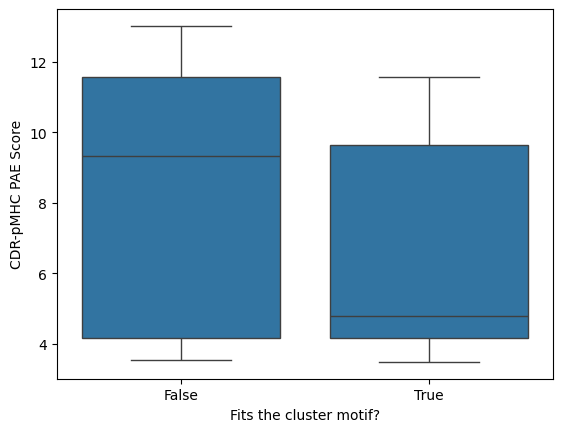

In [18]:
ax = sns.boxplot(confidence_scores, y='cdr_pmhc_pae_score', x='fit_motif')

ax.set_xlabel('Fits the cluster motif?')
ax.set_ylabel('CDR-pMHC PAE Score')

plt.show()

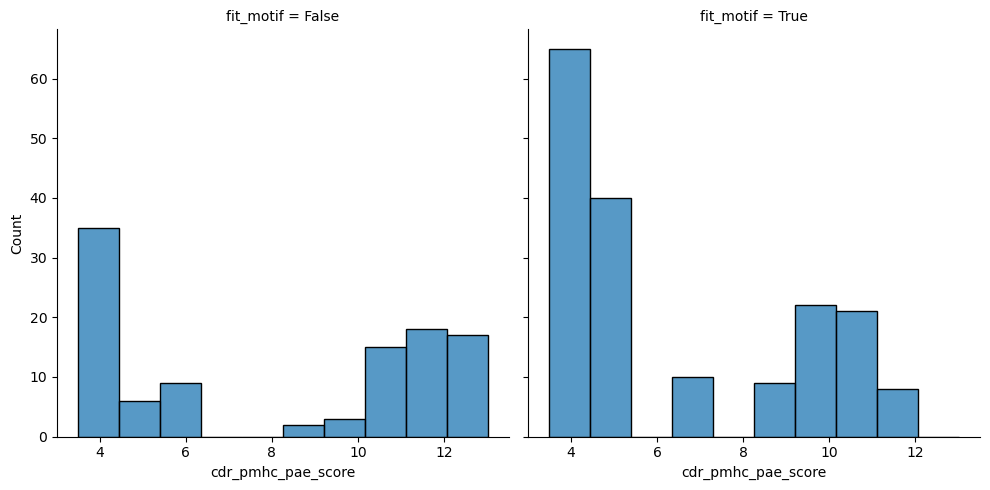

In [19]:
sns.displot(confidence_scores, x='cdr_pmhc_pae_score', col='fit_motif', kind='hist')
plt.show()

In [20]:
pg.mwu(
    confidence_scores[confidence_scores['fit_motif']]['cdr_pmhc_pae_score'],
    confidence_scores[~confidence_scores['fit_motif']]['cdr_pmhc_pae_score'],
    alternative='less',
)

,U-val,alternative,p-val,RBC,CLES
MWU,6724.0,less,0.000087,-0.268136,0.634068


We do see that the confidence scores have a difference between sequences that fit the binding motif and things that do not.

### Blocking by cluster group

We can see that the cluster group itself has a big effect on the effect of mutations.

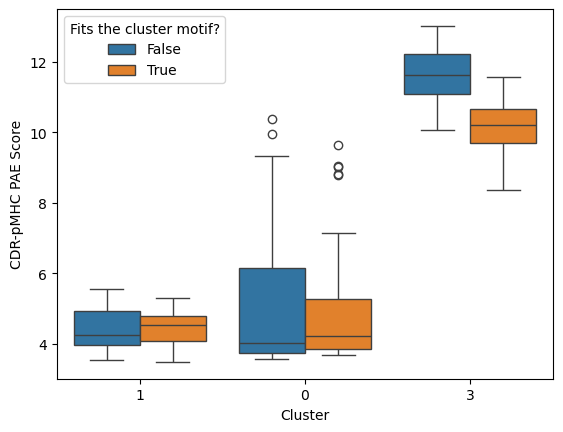

In [21]:
ax = sns.boxplot(confidence_scores, y='cdr_pmhc_pae_score', x='cluster', hue='fit_motif')

ax.set_ylabel('CDR-pMHC PAE Score')
ax.set_xlabel('Cluster')

ax.legend(title='Fits the cluster motif?')

plt.show()

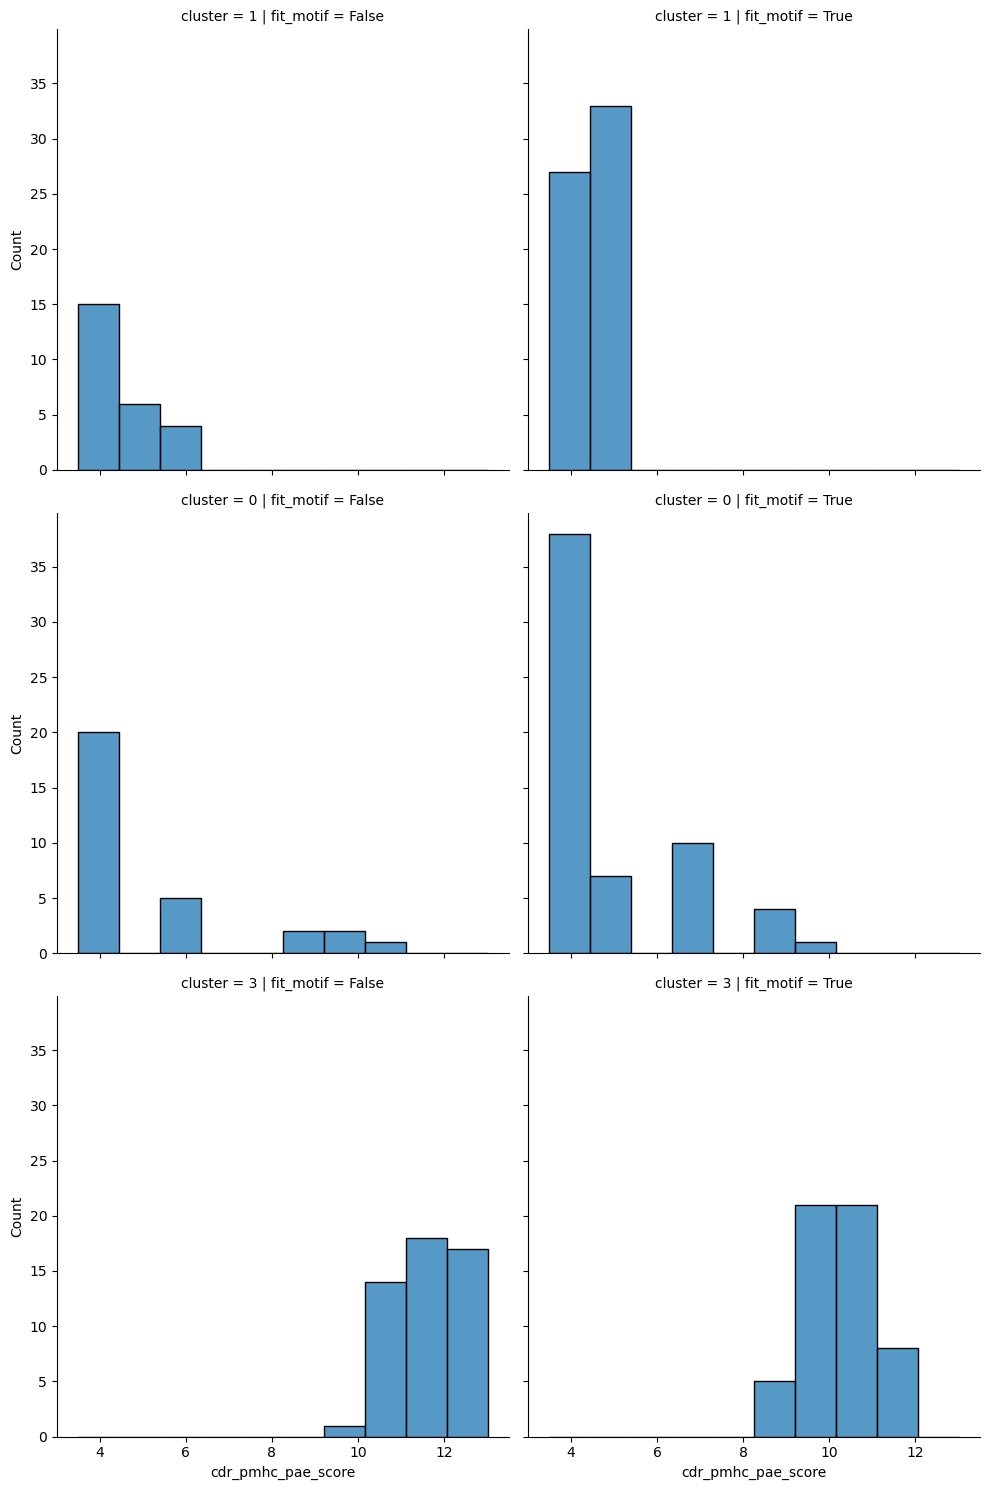

In [22]:
sns.displot(confidence_scores, x='cdr_pmhc_pae_score', row='cluster', col='fit_motif', kind='hist')
plt.show()

In [23]:
pg.anova(confidence_scores, dv='cdr_pmhc_pae_score', between=['cluster', 'fit_motif'])

,Source,SS,DF,MS,F,p-unc,np2
0,cluster,2332.301519,2.0,1166.150760,842.334527,9.400731e-118,0.860109
1,fit_motif,29.463415,1.0,29.463415,21.282026,6.092758e-06,0.072074
2,cluster * fit_motif,26.998377,2.0,13.499188,9.750740,8.113658e-05,0.066444
3,Residual,379.333030,274.0,1.384427,NaN,NaN,NaN


In [24]:
results = []
group_count = 0
for cluster_name, cluster in confidence_scores.groupby('cluster'):
    result = pg.ttest(
        cluster[cluster['fit_motif']]['cdr_pmhc_pae_score'],
        cluster[~cluster['fit_motif']]['cdr_pmhc_pae_score'],
        paired=False,
        alternative='less',
    )
    result['cluster_name'] = cluster_name

    results.append(result)
    group_count += 1

results = pd.concat(results)
results = results.set_index('cluster_name')
results['significant'] = results['p-val'] < (0.05 / group_count)

results

,T,dof,alternative,p-val,CI95%,cohen-d,BF10,power,significant
cluster_name,,,,,,,,,
0,-0.487188,45.920680,less,3.142215e-01,"[-inf, 0.54]",0.119661,0.515,0.132678,False
1,-0.336104,35.743695,less,3.693789e-01,"[-inf, 0.2]",0.090011,0.515,0.102077,False
3,-9.929679,102.257237,less,5.686906e-17,"[-inf, -1.21]",1.939245,7.803e+13,1.000000,True


We only see significance for cluster 3.